# 1) Basic Concepts for Electrochemical Impedance Spectroscopy

In this notebook, we review the main electrical concepts used in EIS:
- Resistance
- AC sinusoidal signals
- Frequency and angular frequency
- Complex numbers and complex impedance
- Ideal resistor
- Ideal capacitor
- Simple RC circuit (series)

We use these concepts to build intuition before working with real EIS data.


## 2. Resistance

**Definition**

Resistance $R$ measures how much a circuit element opposes the flow of electric current.

Ohm’s law:



$$
R = \frac{V}{I}
$$



where:
- $V$ is the voltage (in volts),
- $I$ is the current (in amperes),
- $R$ is the resistance (in ohms, $\Omega$).


For an ideal resistor, $R$ is constant and does not depend on frequency.


In [ ]:
R = 100.0  # ohms
V = 1.0    # volts
I = V / R

print(f"Current (I) = {I} A")

Current (I) = 0.01 A


## 3. AC signals and frequency

In EIS, we apply a small sinusoidal (AC) voltage or current.

A sinusoidal voltage:



$$
v(t) = V_0 \sin(\omega t + \phi)
$$



where:
- $V_0$ is the amplitude,
- $\omega$ is the angular frequency (rad/s),
- $\phi$ is the phase (rad),
- $t$ is time (s).

**Frequency and angular frequency**

Frequency $f$ (in Hz) and angular frequency $\omega$ (in rad/s) are related by:



$$
\omega = 2\pi f
$$



The period $T$ of the signal is:



$$
T = \frac{1}{f}
$$




Angular frequency (omega) = 628.3185307179587 rad/s
Period (T) = 0.01 s


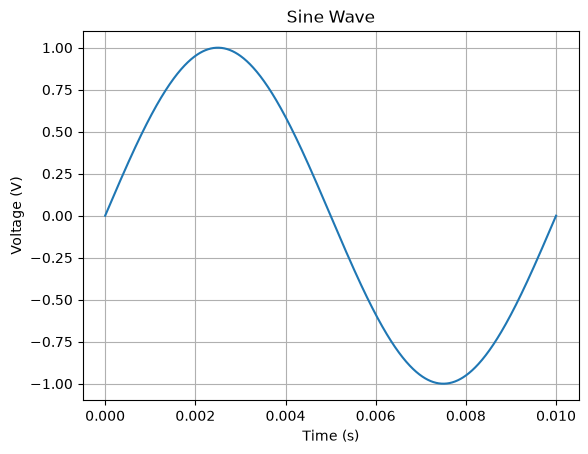

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

V = 1.0    # volts

f = 100.0          # Hz
omega = 2 * np.pi * f
T = 1 / f

print(f"Angular frequency (omega) = {omega} rad/s")
print(f"Period (T) = {T} s")

v = V * np.sin(omega * np.linspace(0, T, 1000))

plt.plot(np.linspace(0, T, 1000), v )
plt.xlabel("Time (s)")
plt.ylabel("Voltage (V)")
plt.title("Sine Wave")
plt.grid(True)
plt.show()

## 4. Complex numbers and complex impedance

To describe AC behavior, we use complex numbers.

A complex number:



$$
z = a + j b
$$



where:
- $a$ is the real part,
- $b$ is the imaginary part,
- $j$ is the imaginary unit ($j^2 = -1$).

**Complex impedance**

Impedance $Z$ generalizes resistance to AC signals:



$$
Z = R + jX
$$



where:
- $R$ is the resistive (real) part,
- $X$ is the reactive (imaginary) part.

Magnitude and phase of $Z$:



$$
|Z| = \sqrt{R^2 + X^2}
$$





$$
\varphi = \arctan\left(\frac{X}{R}\right)
$$




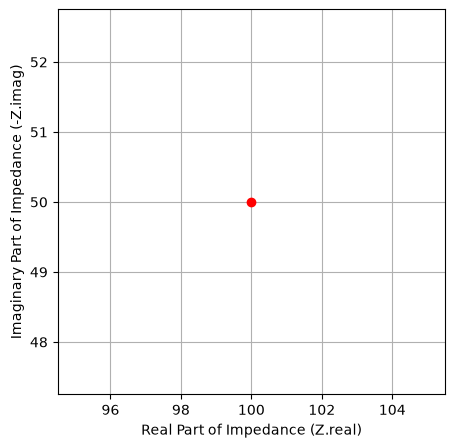

In [ ]:
R = 100.0
X = -50.0
Z = R + 1j * X

plt.figure(figsize=(5,5))
plt.plot(Z.real, -Z.imag, 'ro')
plt.xlabel('Real Part of Impedance (Z.real)')
plt.ylabel('Imaginary Part of Impedance (-Z.imag)')
plt.grid(True)
plt.show()

## 5. Ideal resistor in AC

For an ideal resistor:



$$
Z_R = R
$$



- Purely real impedance.
- Independent of frequency.
- Voltage and current are **in phase** (phase shift $0$ rad).


## 6. Ideal capacitor

A capacitor with capacitance $C$ (in farads) has impedance:



$$
Z_C = \frac{1}{j \omega C} = -\frac{j}{\omega C}
$$



Properties:
- Purely imaginary (reactive) impedance.
- Depends on frequency: $|Z_C| = \frac{1}{\omega C}$.
- Current **leads** voltage by $90^\circ$ (phase $+\pi/2$).


In [ ]:
C = 1e-6      # 1 µF
f = 1000   # Hz
omega = 2 * np.pi * f
Z_C = 1 / (1j * omega * C)

print(f"Impedance of Capacitance (Z_C) = {Z_C}")

Impedance of Capacitance (Z_C) = -159.15494309189535j


## 7. Series RC circuit

Consider a resistor $R$ in series with a capacitor $C$.

Total impedance:



$$
Z_{\text{RC}} = Z_R + Z_C = R + \frac{1}{j \omega C}
$$



Real and imaginary parts:



$$
\Re(Z_{\text{RC}}) = R
$$





$$
\Im(Z_{\text{RC}}) = -\frac{1}{\omega C}
$$



Magnitude and phase:



$$
|Z_{\text{RC}}| = \sqrt{R^2 + \left(\frac{1}{\omega C}\right)^2}
$$





$$
\varphi = \arctan\left( \frac{-1/(\omega C)}{R} \right)
$$



This simple RC circuit is a basic model used in EIS to represent charge transfer resistance and double‑layer capacitance.


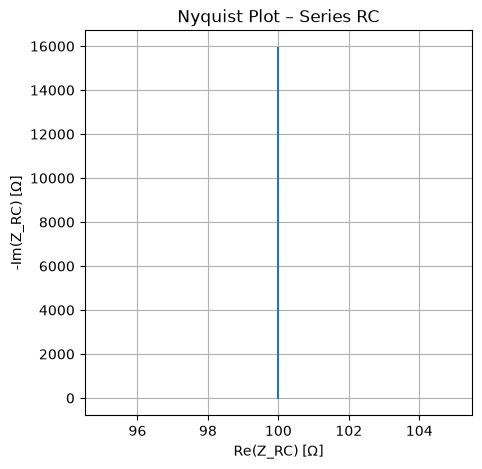

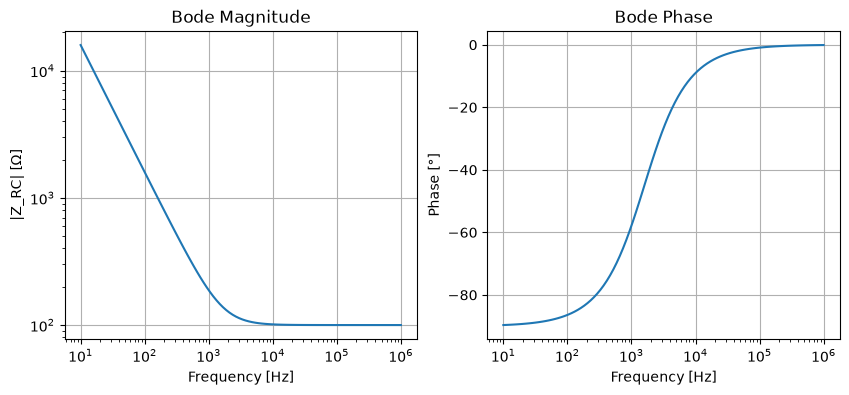

In [ ]:
R = 100.0      # ohms
C = 1e-6       # F
f = np.logspace(1, 6, 100)     # Hz
omega = 2 * np.pi * f

Z_R = R
Z_C = 1 / (1j * omega * C)
Z_RC = Z_R + Z_C
    
abs_Z_RC = abs(Z_RC)
phi_RC = np.angle(Z_RC)

plt.figure(figsize=(5,5))
plt.plot(Z_RC.real, -Z_RC.imag)
plt.xlabel("Re(Z_RC) [Ω]")
plt.ylabel("-Im(Z_RC) [Ω]")
plt.title("Nyquist Plot – Series RC")
plt.grid(True)
plt.show()

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.loglog(f, np.abs(Z_RC))
plt.xlabel("Frequency [Hz]")
plt.ylabel("|Z_RC| [Ω]")
plt.title("Bode Magnitude")
plt.grid(True)

plt.subplot(1,2,2)
plt.semilogx(f, np.angle(Z_RC, deg=True))
plt.xlabel("Frequency [Hz]")
plt.ylabel("Phase [°]")
plt.title("Bode Phase")
plt.grid(True)

plt.show()
